# Finding a hidden-marker matching circuit in Qwen3-14B

## Experiment 4 · executed exploratory notebook

This notebook asks a narrower question than “does the model introspect?”: **after fine-tuning, can we localize a circuit that compares an injected test residual direction with injected demonstration directions and routes the corresponding nonce label?**

The analysis follows the evidential ladder in the full [ARENA induction-head exercises](https://github.com/callummcdougall/ARENA_3.0/blob/main/chapter1_transformer_interp/exercises/part2_intro_to_mech_interp/1.2_Intro_to_Mech_Interp_exercises.ipynb): behavioral capability → activation pattern → causal ablation → counterfactual patching → component/weight evidence. Attention plots nominate hypotheses; they do not establish a circuit.

All model-facing cells were run on H100s with Qwen3-14B in BF16. The notebook embeds the resulting artifacts and reruns the statistical/visual analysis. The exact model runner is `experiment/mechanistic_introspection.py`; the protocol was frozen before Experiment 4 outcomes were opened.

### Learning objectives

By the end, you should be able to:

1. distinguish a **marker-matching head** from a domain-general “introspection head”;
2. explain why an attention stripe is only candidate-generation evidence;
3. interpret held-out mean ablation and counterfactual activation patching;
4. identify selection, prompt, position, layer, vector-family, and intervention-artifact confounds;
5. state what further evidence would strengthen or falsify the circuit hypothesis.

In [1]:
from pathlib import Path
import json, numpy as np, pandas as pd, matplotlib.pyplot as plt

def find_repo_root(start=Path.cwd()):
    for candidate in [start, *start.parents]:
        if (candidate / "public/data/experiment4-results.json").exists():
            return candidate
    raise FileNotFoundError("Run inside the hidden-marker-lab repository")

ROOT = find_repo_root()
RESULTS = json.loads((ROOT / "public/data/experiment4-results.json").read_text())
MECH = ROOT / "experiment/results/experiment4/mechanistic"
RESULTS["status"], RESULTS["model_id"], RESULTS["protocol_frozen_before_results"]

('completed', 'Qwen/Qwen3-14B', True)

## 1. Behavioral boundary conditions before localization

Mechanistic labels are only meaningful relative to a behavioral distribution. The fixed adapters remain strong on Student-t directions and natural residual-activation differences, but they fail at a new token position and later injection layer; prompt paraphrases and different carriers degrade performance. The joint shift is at chance, partly because it includes a layer-24 shift that is already sufficient to eliminate the behavior.

This immediately constrains the claim: any circuit found below implements the trained, site-anchored task. It is not evidence for a prompt-, position-, or layer-invariant faculty.

In [2]:
ood = pd.DataFrame([{
    'condition': r['id'].replace('_', ' '),
    'mean accuracy': r['mean_accuracy'],
    'minimum seed': r['min_accuracy'],
    'maximum seed': r['max_accuracy'],
    'mean margin': r['mean_margin'],
} for r in RESULTS['fixed_adapter_conditions']])
ood.round(3)

condition,mean accuracy,minimum seed,maximum seed,mean margin
id reference,0.936,0.918,0.957,5.187
prompt paraphrase,0.602,0.594,0.609,0.833
different carriers,0.724,0.695,0.746,1.274
content token,0.499,0.492,0.504,0.005
cross position,0.488,0.480,0.496,-0.065
layer 16,0.639,0.629,0.656,0.985
layer 24,0.499,0.496,0.500,0.001
correlated 0 5,0.799,0.789,0.820,2.973
correlated 0 9,0.562,0.551,0.574,0.567
student t 3,0.940,0.926,0.949,5.220


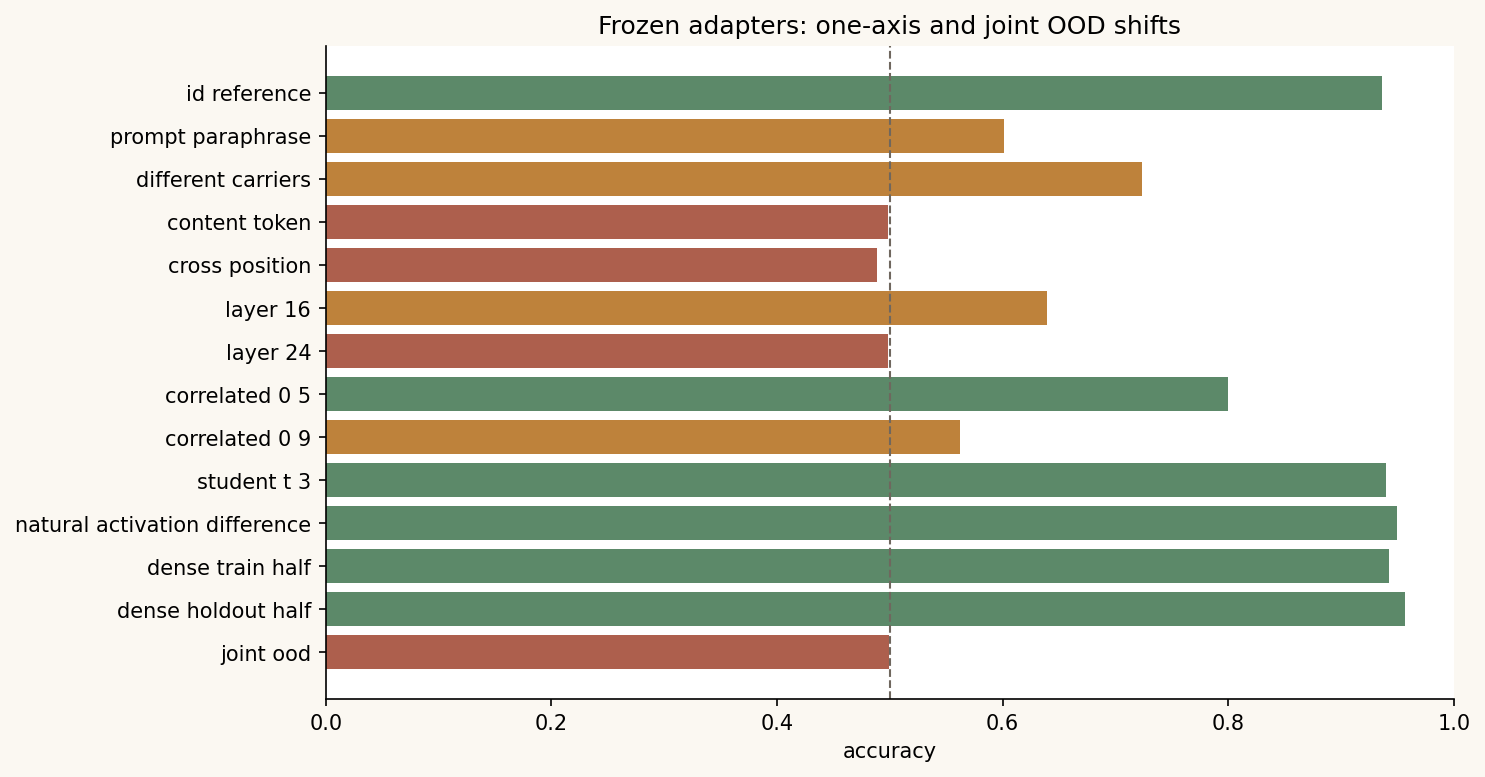

In [3]:
colors = ['#4a7c59' if x >= .75 else '#b77525' if x > .55 else '#a44e3a' for x in ood['mean accuracy']]
ax = ood.plot.barh(x='condition', y='mean accuracy', color=colors, legend=False, figsize=(10, 5.3))
ax.invert_yaxis(); ax.axvline(.5, ls='--', color='#6f675e'); ax.set_xlim(0, 1);

## 2. Stronger direction generalization: an exactly orthogonal held-out span

Fresh Gaussian vectors from the full space do not exclude a detector fitted to the training distribution's span. Three new adapters therefore saw directions only from 2,560 basis dimensions. The reserved 2,560-dimensional complement was never used for localization, same/different, label binding, or checkpoint selection. A signed/permuted block-Walsh-Hadamard transform makes both spans dense in the model basis and exactly orthogonal (maximum numerical cross-dot product (1.86\times10^{-9})).

The preregistered gate required every holdout run to exceed 75% and the mean holdout gap to be at most 10 percentage points.

In [4]:
subspace = pd.DataFrame([{
    'seed': r['seed'], 'trained half': r['train_span']['accuracy'],
    'orthogonal holdout': r['holdout_span']['accuracy'], 'gap': r['holdout_gap'],
    'trials per half': r['train_span']['n_trials'],
} for r in RESULTS['subspace']['runs']])
subspace.round(4)

seed,trained half,orthogonal holdout,gap,trials per half
20260830,0.9500,0.9399,0.0100,4096
20260831,0.9661,0.9468,0.0193,4096
20260832,0.9583,0.9551,0.0032,4096


In [5]:
print(f"Gate passed: {RESULTS['subspace']['passed']}")
print(f"Mean trained-half accuracy: {RESULTS['subspace']['mean_train_accuracy']:.4%}")
print(f"Mean orthogonal-holdout accuracy: {RESULTS['subspace']['mean_holdout_accuracy']:.4%}")
print(f"Mean gap: {RESULTS['subspace']['mean_holdout_gap']:.2%}")

Gate passed: True
Mean trained-half accuracy: 95.8089%
Mean orthogonal-holdout accuracy: 94.7266%
Mean gap: 1.08%

## 3. What would count as an “introspection head”?

The literal task algorithm is closer to induction than to unconstrained self-report:

1. retain/sketch the demonstration interventions at their carrier tokens;
2. compare the test intervention with both sketches;
3. route the matched demonstration's arbitrary label to the answer.

A head that performs step 2 is a **marker-matching head**. Calling it an “introspection head” would imply much more: robustness across internal phenomena, sites, prompts, and intervention mechanisms. The present experiments cannot establish that broader property.

Candidate criteria used here:

- train-minus-base attention from the test-period query to the same-vector demonstration;
- held-out mean ablation harms task margin without comparable general-LM harm;
- counterfactual patching from the opposite-vector trial moves the answer in the predicted direction;
- the same architectural head recurs across independent training seeds;
- no-test, base-model, random-head, and matched-group controls are null.

## 4. Candidate generation: a marker-matching attention pattern

For each trial and head, define

\[
s_h = a_h(t_{test},t_{matching\ demo}) - a_h(t_{test},t_{other\ demo}).
\]

The visible carrier is identical, and vector identity, mapping, demonstration order, and option order are counterbalanced. A positive score therefore says the test-token query preferentially attends to the demonstration token carrying the same injected vector.

**Exercise.** Before viewing the heatmap, predict which layers can show a causal marker match when the intervention enters at `resid_pre` block 20. Why should layers 0–19 be excluded from the candidate set?

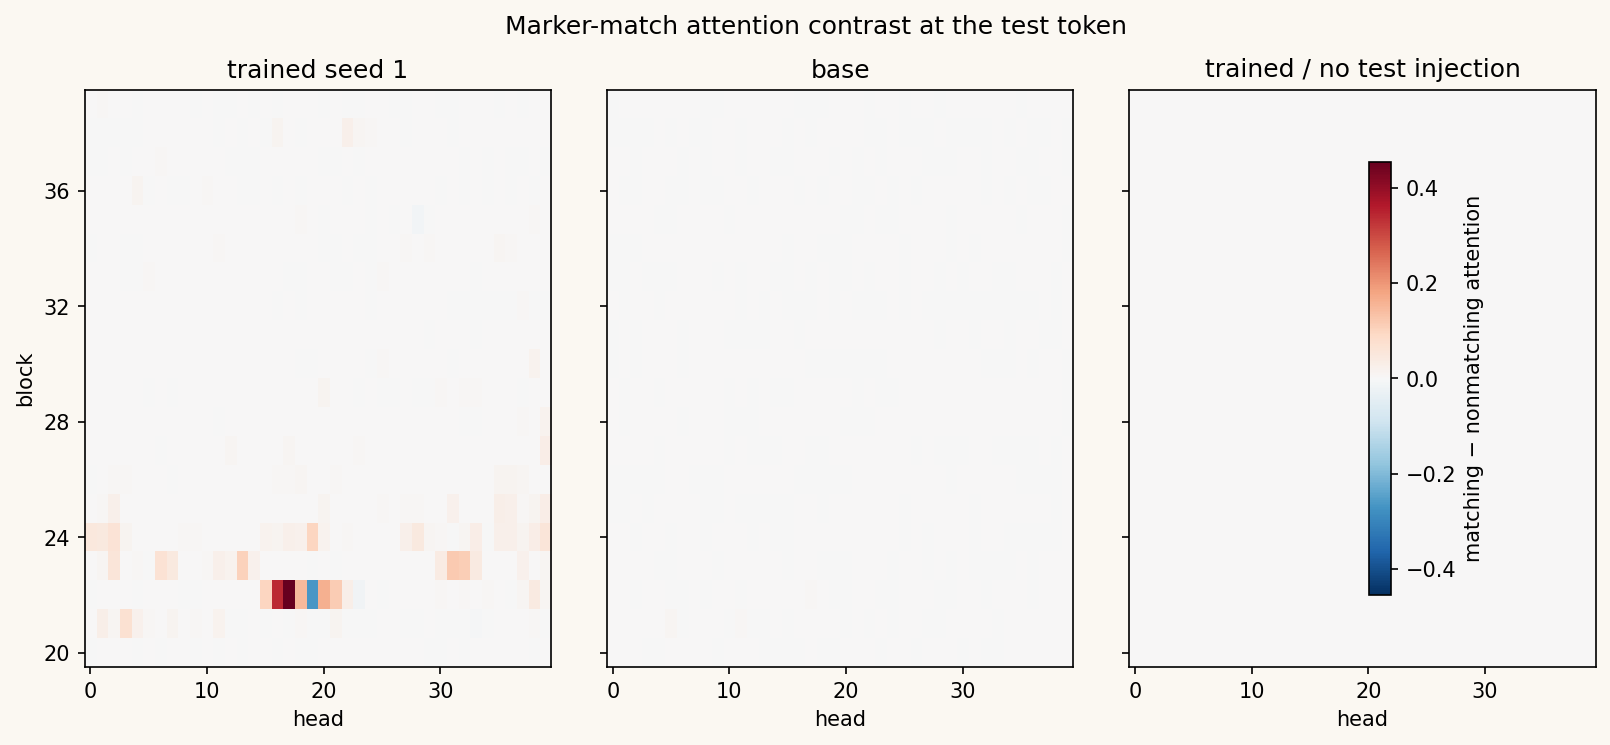

In [6]:
def score_matrix(artifact):
    m = np.zeros((40, 40))
    for row in artifact['head_scores']:
        m[row['layer'], row['head']] = row['match_probability_contrast']
    return m
# Plot trained, base, and no-test matrices; blocks 20–39 only.

In [7]:
matcher = RESULTS['mechanistic']['head_summaries'][0]
spec = RESULTS['mechanistic']['head_22_17_specificity']
pd.DataFrame({
 'condition': ['trained seed 1','trained seed 2','trained seed 3','base','trained / no test'],
 'block 22 head 17 match contrast': [*matcher['attention']['per_seed'], spec['base_primary_match_contrast'], spec['trained_no_test_match_contrast']]
}).round(4)

condition,block 22 head 17 match contrast
trained seed 1,0.4544
trained seed 2,0.3232
trained seed 3,0.4104
base,0.0057
trained / no test,0.0000


The same head index (block 22, head 17) is the strongest probability-contrast matcher in all three adapters. The effect is small in the base model and exactly cancels when no test intervention is injected. This is strong feature evidence but remains non-causal: attention probability does not show that the value written by the head is used.

## 5. Held-out causal test: position-specific mean ablation

Candidates were selected on seed 20260820 and discovery episodes. Confirmation uses a disjoint episode seed and two other independently trained adapters. At every sequence position, one head's pre-`o_proj` value is replaced by its within-batch, position-specific mean. This is less distribution-shifting than zero ablation and removes trial-specific marker information.

General-language control NLL is measured on held-out synthetic paragraphs. It is not a perfect natural-corpus control, but it helps detect globally destructive ablations.

In [8]:
heads = RESULTS['mechanistic']['head_summaries']
ablation = pd.DataFrame([{
 'component': f"{h['layer']}.{h['head']} · {h['role_hypothesis']}",
 'mean accuracy drop': h['mean_ablation']['mean_accuracy_drop'],
 'mean margin drop': h['mean_ablation']['mean_margin_drop'],
 'mean general-LM NLL change': np.mean(h['mean_ablation']['per_seed_general_lm_nll_change']),
} for h in heads])
ablation.round(4)

component,mean accuracy drop,mean margin drop,mean general-LM NLL change
22.17 · marker matcher,0.0716,1.6556,-0.0028
20.29 · early marker processor,0.0716,1.5881,-0.0093
23.36 · answer router,0.0378,1.8685,-0.0027


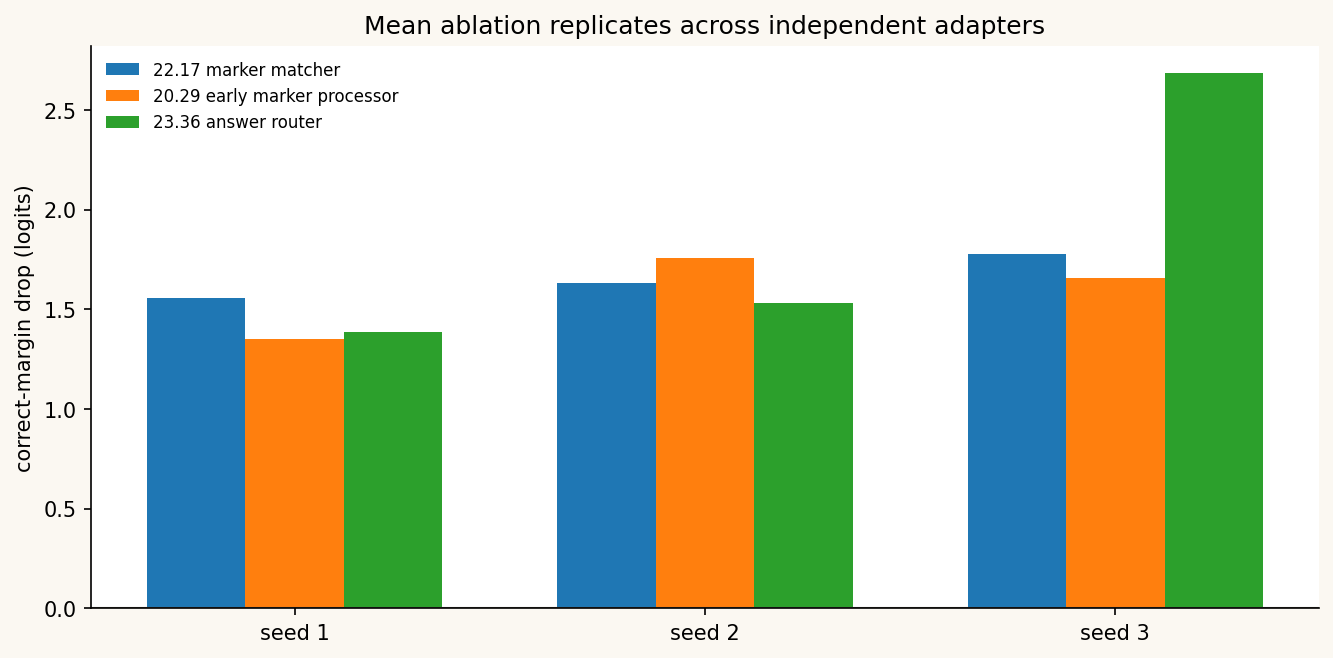

In [9]:
# Per-seed held-out margin effects for the three proposed components.

## 6. Counterfactual activation patching: does the head carry vector identity?

Each prompt has two trials with identical visible tokens and demonstration interventions; only the test vector differs. For a target `v2` trial, replace one head's output **at the test marker token only** with its cached value from the paired `v1` trial, and vice versa. If the head carries task-relevant marker identity, the target-correct margin should fall. Because no text changes, this avoids label and option confounds.

This is more specific than ablation. It tests the direction of information flow, not merely necessity.

In [10]:
patching = pd.DataFrame([{
 'component': f"{h['layer']}.{h['head']} · {h['role_hypothesis']}",
 'mean target-margin reduction': h['counterfactual_patch']['mean_margin_reduction'],
 'answer-flip fraction': h['counterfactual_patch']['mean_answer_flip_fraction'],
 'number of replicated seeds': len(h['counterfactual_patch']['per_seed_margin_reduction']),
} for h in heads if h['counterfactual_patch']])
patching.round(4)

component,mean target-margin reduction,answer-flip fraction,number of replicated seeds
22.17 · marker matcher,3.3166,0.3086,3
20.29 · early marker processor,2.0352,0.1966,3
23.36 · answer router,0.3599,0.0938,1


In [11]:
spec = RESULTS['mechanistic']['head_22_17_specificity']
print(f"Head 22.17 trained patch effect: {heads[0]['counterfactual_patch']['mean_margin_reduction']:+.3f} logits")
print(f"Head 22.17 base-model patch effect: {spec['base_counterfactual_patch_margin_reduction']:+.3f} logits")
print(f"Trained control head 22.8 patch effect: {spec['trained_control_head_22_8_patch_margin_reduction']:+.3f} logits")

Head 22.17 trained patch effect: +3.317 logits
Head 22.17 base-model patch effect: -0.009 logits
Trained control head 22.8 patch effect: -0.009 logits

## 7. One head or a redundant circuit?

ARENA's induction exercises warn that effective circuits can be distributed across several heads. Six neighboring block-22 heads with high marker-match scores were mean-ablated together after discovery. Six matched block-22 control heads were treated identically.

In [12]:
pd.DataFrame([
 {'group':'marker-match cluster', **RESULTS['mechanistic']['matcher_group']},
 {'group':'matched control cluster', **RESULTS['mechanistic']['matched_control_group']},
])[['group','members','accuracy_drop','margin_drop','general_lm_nll_change']]

group,members,accuracy drop,margin drop,general-LM NLL change
marker-match cluster,"22.15, 22.16, 22.17, 22.18, 22.20, 22.21",0.2578,4.0796,-0.0181
matched control cluster,"22.1, 22.3, 22.5, 22.8, 22.10, 22.12",0.0000,-0.0156,-0.0141


The marker-match cluster removes 25.8 percentage points of accuracy and 4.08 logits of correct margin; the matched control cluster changes neither. General-LM NLL changes are similar in magnitude and slightly negative for both groups, so the task effect is not explained by generic language degradation. The individual head is real, but the algorithm is redundant.

## 8. Best current circuit hypothesis

The evidence supports this **functional decomposition**, not a complete reverse-engineering of every weight path:

```
block 20 heads (notably 20.29)
    convert the injected residual delta into a usable low-rank marker sketch
                    │
                    ▼
block 22 matcher cluster (notably 22.17)
    Q(test-period sketch) matches K(demonstration-period sketch)
                    │
                    ▼
block 23 routing heads (notably 23.36)
    carry the selected demonstration/test state into later answer computation
                    │
                    ▼
later LoRA attention + MLPs select the nonce option
```

Why this ordering?

- 20.29 is causal and patchable but has no same-vector attention pattern at block 20, consistent with early feature construction.
- 22.17 has the replicated same-vector attention pattern, mean-ablation effect, and the strongest test-token counterfactual patch effect.
- 23.36 strongly attends from answer computation to the test position and is necessary, but patching only its test-token output has a smaller effect, consistent with downstream routing.

The LoRA Q/K delta row spaces are aligned for early and matching components, but this weight statistic is only supportive: Qwen3 uses RMSNorm, RoPE, GQA, nonlinear downstream computation, and base-plus-LoRA weights. A full QK/OV factorization analogous to a two-layer induction model would require position-conditioned effective weights and explicit composition through the intervening blocks.

## 9. Confounds and what would be convincing

| Confound | Test here | Result | Remaining risk |
|---|---|---|---|
| label/option shortcut | both vectors, mapping/demo/option counterbalancing | primary behavior and causal effects survive | patching analysis uses the same visible prompt, which is stronger |
| memorized direction list | online vectors + exact orthogonal held-out span | 94.73% mean holdout accuracy | still one structured dense basis partition |
| Gaussian coordinate artifact | Student-t and natural activation-difference directions | 94.0% and 94.9% | not every residual distribution or covariance regime |
| attention-pattern illusion | held-out mean ablation + counterfactual patching | replicated causal effects | ablations do not fully identify upstream/downstream composition |
| generic head importance | general-LM NLL + same-layer controls | control effects are null | LM corpus is synthetic and small |
| single lucky training run | three independent adapters | head 22.17 recurs at same index | same base model and training recipe bias convergence |
| injection absence/norm cue | no-test screen and earlier null controls | attention match and behavior vanish | external additive hooks remain unlike endogenous features |
| domain-general introspection | prompt/position/layer OOD suite | fails badly on several axes | this directly argues against the broad claim |

### Convincing positive evidence beyond this notebook

1. Train on randomized injection layers and token sites, then recover the same algorithm or a predictable equivariant circuit on unseen sites.
2. Replace additive hooks with endogenous latent events (e.g. naturally occurring feature activations) and demonstrate calibrated reporting without task-specific carrier scaffolding.
3. Perform path patching: 20.29 → 22.17 Q/K inputs → 23.36/later answer components, with mediation accounting for most of the total causal effect.
4. Reverse-engineer the position-conditioned QK kernel and show it computes same-direction similarity across Gaussian, natural, correlated, and held-out-span vectors.
5. Replicate across base checkpoints, LoRA ranks, full fine-tuning, prompt families, and model families.

### Convincing negative evidence

- no head/circuit survives selection-corrected held-out causal tests;
- circuit indices and functions vary arbitrarily across seeds;
- matched random patches have the same effect as counterfactual marker patches;
- performance disappears outside a narrow token/layer/prompt template;
- a simple detector of hook-specific norm, dtype, or normalization artifacts predicts the response as well as vector identity.

The present result is mixed: it is positive for a stable, causal **marker-matching circuit**, and negative for calling that circuit a general introspection mechanism.

## 10. Suggested exercises and follow-up guidelines

### Exercise A — path-specific patching

Patch only head 20.29's contribution into the Q or K input of 22.17. Compare with patching its contribution into V. A marker-sketch → matcher account predicts a larger Q/K-mediated effect.

### Exercise B — position-conditioned QK kernel

At fixed relative positions, estimate

\[
K(v_i,v_j)=q_{22.17}(v_i)^\top k_{22.17}(v_j)
\]

after RMSNorm and RoPE. Test whether (K(v,v)-K(v,u)) stays positive for unseen correlated and natural directions. Use held-out episodes for every fitted diagnostic.

### Exercise C — selection correction

Repeat candidate selection on seed 2, test on seed 3, then reverse. Report rank overlap and causal-effect correlation. Do not use the confirmation split to redefine the candidate list.

### Exercise D — endogenous-feature transfer

Identify a naturally varying residual feature, define nonce labels in context from high/low or feature-A/feature-B examples, and ask the model to report it. Match visible text and control downstream behavioral consequences. This is substantially closer to introspection than an externally injected random vector.

### Guidelines

- Always balance labels, options, demonstration order, vector identity, and prompt variants.
- Separate discovery, confirmation, and final OOD sets at the episode seed level.
- Report margins and full trial ledgers, not only accuracy.
- Prefer counterfactual patching and path patching to interpreting attention weights.
- Treat zero/mean ablation disagreement as a warning about distribution shift.
- Do not promote a task-specific marker detector to “introspection” without cross-domain transfer.

## 11. Reproducibility

GPU commands used the public cached `Qwen/Qwen3-14B` revision recorded in the result artifact, BF16 evaluation, official chat template, no sampling, and native PyTorch hooks at block `resid_pre` / attention pre-`o_proj`.

```bash
# Attention/weight screen
python experiment/mechanistic_introspection.py --mode screen \
  --adapter /path/to/best-adapter.pt --model-condition seed-20260820 \
  --output-dir /path/to/screen --seed 20260910 --episodes 32 --orbit 1

# Held-out position-specific mean ablation
python experiment/mechanistic_introspection.py --mode causal --ablation-type mean \
  --adapter /path/to/best-adapter.pt --model-condition seed-20260820 \
  --output-dir /path/to/causal --seed 20260920 --episodes 64 --orbit 2 \
  --candidates 22.17,22.16,20.29,23.36

# Counterfactual test-token patching
python experiment/mechanistic_introspection.py --mode patch \
  --adapter /path/to/best-adapter.pt --model-condition seed-20260820 \
  --output-dir /path/to/patch --seed 20260920 --episodes 64 --orbit 2 \
  --candidates 22.17,20.29,23.36
```

The dashboard exposes every categorical OOD and subspace trial, every angular-morph diagnostic trial, the frozen protocol, this notebook, and the source runners.